# Ellingham Diagrams

An [Ellingham diagram](https://en.wikipedia.org/wiki/Ellingham_diagram) shows the Gibbs energy change $\Delta G^\circ$ of oxidation reactions, per mole of $\mathrm{O_2}$, as a function of temperature. The lower a line lies, the more stable the oxide: a metal reduces the oxides whose lines lie above its own.

Where a metal and its oxide coexist, the oxygen chemical potential is fixed by the two condensed phases. With pure oxygen gas at 1 atm as the reference state of oxygen,

$$\Delta G^\circ = 2\left(\mu_\mathrm{O} - \mu_\mathrm{O}^\mathrm{ref}\right) = RT \ln p_\mathrm{O_2},$$

where $p_\mathrm{O_2}$ (in atm) is the oxygen partial pressure at which the metal and the oxide are in equilibrium. So each line of the diagram is the oxygen potential of a two-phase equilibrium, which pycalphad computes directly from a database. No reaction has to be written down, and oxides that are not stoichiometric, such as wüstite, are handled as the database models them.

The databases used here:

* Cu-O: L. Schramm, G. Behr, W. Löser and K. Wetzig, *J. Phase Equilib. Diffus.* 26 (2005) 605–612
* Fe-O: from L. Kjellqvist and M. Selleby, *J. Phase Equilib. Diffus.* 31 (2010) 113–134
* Al-Fe-O: G. Lindwall, X. L. Liu and Z.-K. Liu (2015); it has no liquid aluminum, so the Al line is computed only below the melting point of aluminum (933 K).

In [1]:
from pycalphad import Database, equilibrium, variables as v
import numpy as np
import matplotlib.pyplot as plt

R = 8.3145  # J/mol/K
dbf_cu = Database('../databases/Cu-O.tdb')
dbf_fe = Database('../databases/Fe-O.tdb')
dbf_al = Database('../databases/Al-Fe-O.tdb')

## The reference state of oxygen

The reference is pure $\mathrm{O_2}$ gas at 1 atm: the oxygen chemical potential of an equilibrium of pure oxygen in the gas phase, at each temperature.

In [2]:
def oxygen_reference(dbf, temperatures):
    """Chemical potential of O (J/mol) in pure oxygen gas at 1 atm."""
    eq = equilibrium(dbf, ['O'], ['GAS'], {v.N: 1, v.P: 101325, v.T: temperatures})
    return eq.MU.sel(component='O').squeeze().values

## The oxygen potential of a metal-oxide equilibrium

The equilibrium is computed for the condensed phases only (the gas phase is left out), at an overall composition inside the two-phase region of the metal and the oxide. At each temperature the stable phases are checked, and only temperatures where exactly the expected two phases are stable are kept: away from those, the oxygen potential belongs to another equilibrium (for example to the single oxide phase).

In [3]:
def ellingham_line(dbf, metal, x_oxygen, temperatures, phase_pairs):
    """Delta G (J per mol O2) of the equilibria between the phases in phase_pairs, at X(O) = x_oxygen.

    Returns the temperatures, Delta G and the stable phases at each temperature; Delta G is NaN where the
    stable phases are not one of phase_pairs."""
    phases = [ph for ph in dbf.phases if ph != 'GAS']
    eq = equilibrium(dbf, [metal, 'O', 'VA'], phases,
                     {v.N: 1, v.P: 101325, v.T: temperatures, v.X('O'): x_oxygen})
    mu_O = eq.MU.sel(component='O').squeeze().values
    delta_G = 2 * (mu_O - oxygen_reference(dbf, temperatures))
    stable = []
    for names, amounts in zip(eq.Phase.squeeze().values, eq.NP.squeeze().values):
        stable.append(frozenset(str(p) for p, n in zip(names, amounts) if p != '' and n > 1e-8))
    keep = np.array([s in phase_pairs for s in stable])
    return temperatures, np.where(keep, delta_G, np.nan), stable

## The oxidation reactions

Each entry gives the database, the metal, an overall oxygen mole fraction inside the two-phase region, and the phase pairs (as named in the database) that make up the line. Where the metal melts or changes structure, the line continues with the other metal phase; the iron line changes from magnetite to wüstite at the eutectoid temperature, where wüstite becomes stable (about 814 K in this database).

In [4]:
T = np.arange(300., 1801., 10.)
lines = [
    (r'$4\,\mathrm{Cu} + \mathrm{O_2} \rightarrow 2\,\mathrm{Cu_2O}$', dbf_cu, 'CU', 0.1,
     [{'FCC_A1', 'CU2O'}, {'IONIC_LIQ', 'CU2O'}]),
    (r'$2\,\mathrm{Cu_2O} + \mathrm{O_2} \rightarrow 4\,\mathrm{CuO}$', dbf_cu, 'CU', 0.4,
     [{'CU2O', 'CUO'}]),
    (r'$2\,\mathrm{Fe} + \mathrm{O_2} \rightarrow 2\,\mathrm{FeO}$', dbf_fe, 'FE', 0.2,
     [{'BCC_A2', 'HALITE'}, {'FCC_A1', 'HALITE'}]),
    (r'$\frac{3}{2}\,\mathrm{Fe} + \mathrm{O_2} \rightarrow \frac{1}{2}\,\mathrm{Fe_3O_4}$', dbf_fe, 'FE', 0.2,
     [{'BCC_A2', 'SPINEL'}]),
    (r'$6\,\mathrm{FeO} + \mathrm{O_2} \rightarrow 2\,\mathrm{Fe_3O_4}$', dbf_fe, 'FE', 0.56,
     [{'HALITE', 'SPINEL'}]),
    (r'$4\,\mathrm{Fe_3O_4} + \mathrm{O_2} \rightarrow 6\,\mathrm{Fe_2O_3}$', dbf_fe, 'FE', 0.59,
     [{'SPINEL', 'CORUNDUM'}]),
    (r'$\frac{4}{3}\,\mathrm{Al} + \mathrm{O_2} \rightarrow \frac{2}{3}\,\mathrm{Al_2O_3}$', dbf_al, 'AL', 0.2,
     [{'FCC_A1', 'CORUNDUM'}]),
]
results = []
for label, dbf, metal, x_O, pairs in lines:
    temps = T if metal != 'AL' else T[T < 933]
    results.append((label, ellingham_line(dbf, metal, x_O, temps, [frozenset(p) for p in pairs])))

## The diagram

The dotted lines are the oxygen partial pressures $RT \ln p_\mathrm{O_2}$: an oxide is reduced where the oxygen partial pressure lies below its line.

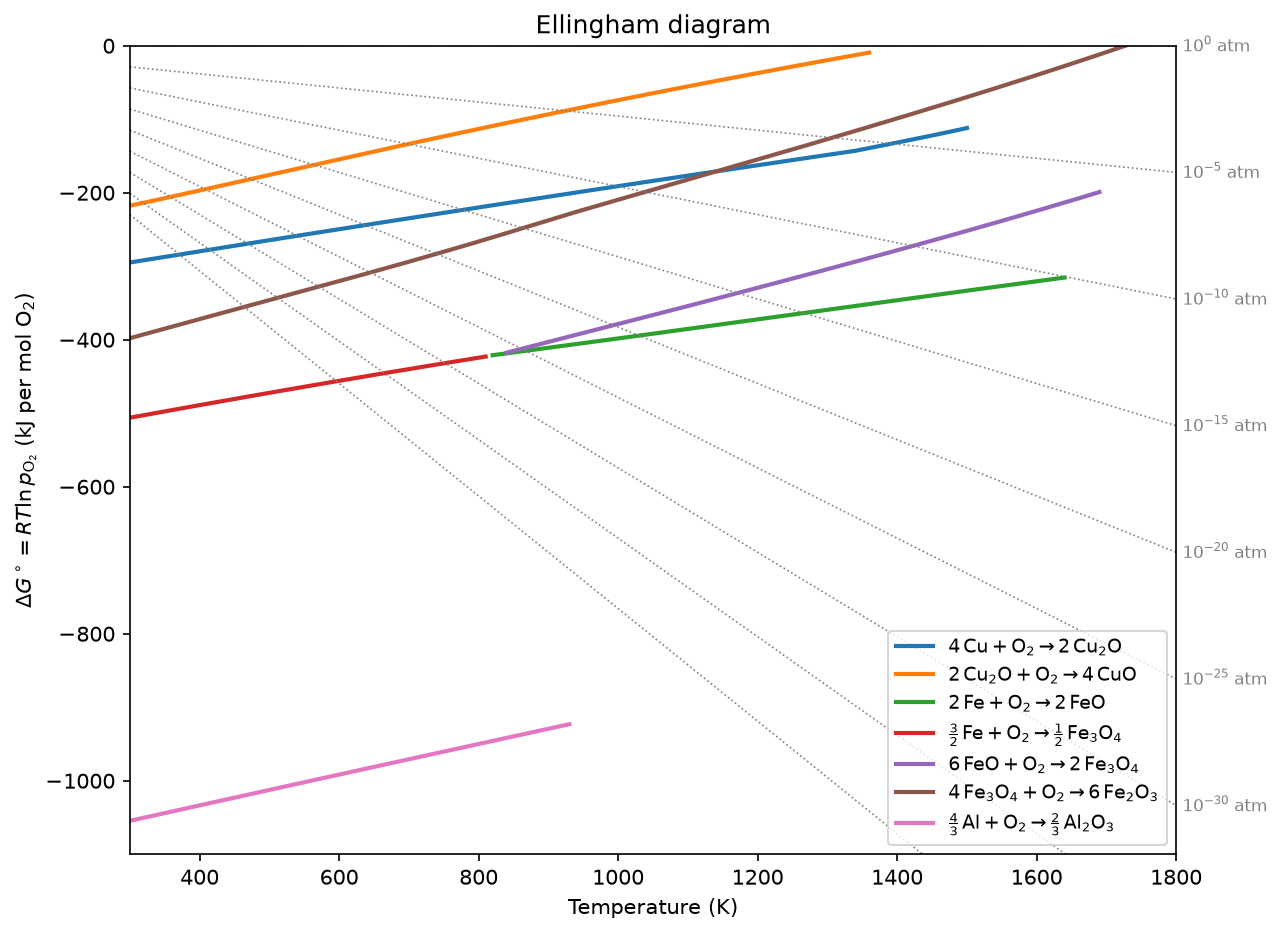

In [5]:
fig, ax = plt.subplots(figsize=(9, 7), dpi=150)
for label, (temps, delta_G, stable) in results:
    ax.plot(temps, delta_G / 1000, lw=2, label=label)
for exponent in range(-40, 1, 5):
    ax.plot(T, R * T * np.log(10.0 ** exponent) / 1000, ':', color='gray', lw=0.8)
    ax.annotate(f'$10^{{{exponent}}}$ atm', (T[-1], R * T[-1] * np.log(10.0 ** exponent) / 1000),
                fontsize=8, color='gray', xytext=(3, 0), textcoords='offset points', va='center')
ax.set_xlim(T[0], T[-1])
ax.set_ylim(-1100, 0)
ax.set_xlabel('Temperature (K)')
ax.set_ylabel(r'$\Delta G^\circ = RT \ln p_\mathrm{O_2}$ (kJ per mol O$_2$)')
ax.set_title('Ellingham diagram')
ax.legend(loc='lower right', fontsize=9)
plt.show()

## Reading the diagram

The oxygen partial pressure at which a metal and its oxide coexist follows from the line: $p_\mathrm{O_2} = \exp(\Delta G^\circ / RT)$. For example, at 1000 K:

In [6]:
for label, (temps, delta_G, stable) in results:
    j = np.searchsorted(temps, 1000.)
    if j < len(temps) and temps[j] == 1000. and np.isfinite(delta_G[j]):
        phases = ' + '.join(sorted(stable[j]))
        print(f'{phases:20s} Delta G = {delta_G[j] / 1000:8.1f} kJ/mol O2, p_O2 = {np.exp(delta_G[j] / (R * 1000.)):.2e} atm')

CU2O + FCC_A1        Delta G =   -191.0 kJ/mol O2, p_O2 = 1.06e-10 atm
CU2O + CUO           Delta G =    -74.0 kJ/mol O2, p_O2 = 1.36e-04 atm
BCC_A2 + HALITE      Delta G =   -398.2 kJ/mol O2, p_O2 = 1.58e-21 atm
HALITE + SPINEL      Delta G =   -378.7 kJ/mol O2, p_O2 = 1.66e-20 atm
CORUNDUM + SPINEL    Delta G =   -209.5 kJ/mol O2, p_O2 = 1.14e-11 atm


Copper(I) oxide is reduced at oxygen partial pressures below about $10^{-10}$ atm at 1000 K, while wüstite needs less than about $10^{-21}$ atm. Aluminum lies far below both: it reduces iron oxides, the basis of the thermite reaction.